# Further Statistical Tests

Stress-tests for the main-finding regression in `main_finding.ipynb`
(`|funding_rate| ~ days_since_launch`, pooled across all 13 markets). This
notebook doesn't replace that result — it checks whether it survives more
scrutiny than a single pooled OLS line, and asks whether a straight line is
even the right shape for the decay in the first place.

Five checks: cluster-robust standard errors, leave-one-market-out, a sign
test (does funding revert toward neutral, not just shrink in size), a
no-assumptions smoothed curve over the raw data, and an exponential decay
fit (ties to AHJ's funding-intensity parameter, κ).

Loads only CSVs from `kalshi_data/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.optimize import curve_fit
from pathlib import Path

DATA = Path("kalshi_data")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.6,
    "font.size": 10,
})

C_KALSHI = "#0072B2"     # Okabe-Ito blue
C_OKX = "#D55E00"        # vermillion
C_COINGECKO = "#009E73"  # green

In [2]:
funding = pd.read_csv(DATA / "funding_rates_all.csv")
funding["funding_time"] = pd.to_datetime(funding["funding_time"], utc=True)

launch_date = funding.groupby("market_ticker")["funding_time"].min()
active_tickers = sorted(launch_date.index)

funding["days_since_launch"] = (
    funding["funding_time"] - funding["market_ticker"].map(launch_date)
).dt.total_seconds() / 86400

reg_df = funding[funding["market_ticker"].isin(active_tickers)].copy()
reg_df["abs_funding_bps"] = reg_df["funding_rate"].abs() * 1e4

def short_name(ticker):
    return ticker.replace("KX", "").replace("PERP", "")

print(f"{len(reg_df)} observations across {len(active_tickers)} markets")

2539 observations across 13 markets


## 1. Cluster-robust standard errors

The main-finding regression uses `HC1` (heteroskedasticity-robust) standard
errors, which fix *unequal variance* across observations but not
*non-independence within a market over time* — every 8-hour reading from the
same coin is currently treated as if it were as independent as a reading from
a different coin entirely. Clustering by `market_ticker` treats each of the
13 markets as one independent unit instead, which is the honest way to size
the uncertainty here.

In [3]:
model_hc1 = smf.ols("abs_funding_bps ~ days_since_launch", data=reg_df).fit(cov_type="HC1")
model_cluster = smf.ols("abs_funding_bps ~ days_since_launch", data=reg_df).fit(
    cov_type="cluster", cov_kwds={"groups": reg_df["market_ticker"]}
)

coef = model_hc1.params["days_since_launch"]
print(f"{'':28} {'coef':>10} {'std err':>10} {'p-value':>12}")
print(f"{'HC1 (main_finding.ipynb)':28} {coef:10.4f} "
      f"{model_hc1.bse['days_since_launch']:10.4f} {model_hc1.pvalues['days_since_launch']:12.2e}")
print(f"{'Clustered by market (n=13)':28} {model_cluster.params['days_since_launch']:10.4f} "
      f"{model_cluster.bse['days_since_launch']:10.4f} {model_cluster.pvalues['days_since_launch']:12.2e}")

                                   coef    std err      p-value
HC1 (main_finding.ipynb)        -0.0117     0.0010     9.30e-30
Clustered by market (n=13)      -0.0117     0.0033     3.60e-04


## 2. Leave-one-market-out

Rerun the same regression 13 times, each time dropping one market entirely.
If the slope's sign and significance survive every single removal, the
result isn't being carried by any one coin.

In [4]:
loo_rows = []
for ticker in active_tickers:
    sub = reg_df[reg_df["market_ticker"] != ticker]
    m = smf.ols("abs_funding_bps ~ days_since_launch", data=sub).fit(cov_type="HC1")
    loo_rows.append({
        "dropped": short_name(ticker),
        "coef": m.params["days_since_launch"],
        "p_value": m.pvalues["days_since_launch"],
    })

loo_df = pd.DataFrame(loo_rows)
full_coef = model_hc1.params["days_since_launch"]
print(f"full-sample coefficient: {full_coef:.4f}")
print(f"leave-one-out range:     {loo_df['coef'].min():.4f} to {loo_df['coef'].max():.4f}")
print(f"all 13 still negative:   {(loo_df['coef'] < 0).all()}")
print(f"all 13 still p < 0.01:   {(loo_df['p_value'] < 0.01).all()}")
loo_df.sort_values("coef")

full-sample coefficient: -0.0117
leave-one-out range:     -0.0130 to -0.0097
all 13 still negative:   True
all 13 still p < 0.01:   True


,dropped,coef,p_value
1,BTC,-0.012970,1.487798e-37
6,LINK,-0.012789,6.408378e-31
2,DOGE,-0.012313,4.092990e-29
12,ZEC,-0.012266,1.015361e-29
8,NEAR,-0.012253,1.587761e-29
9,SOL,-0.012246,2.182891e-28
7,LTC,-0.012245,7.442146e-29
10,SUI,-0.011722,1.935471e-26
3,ETH,-0.011617,4.352904e-26
4,HYPE,-0.011053,9.182399e-27


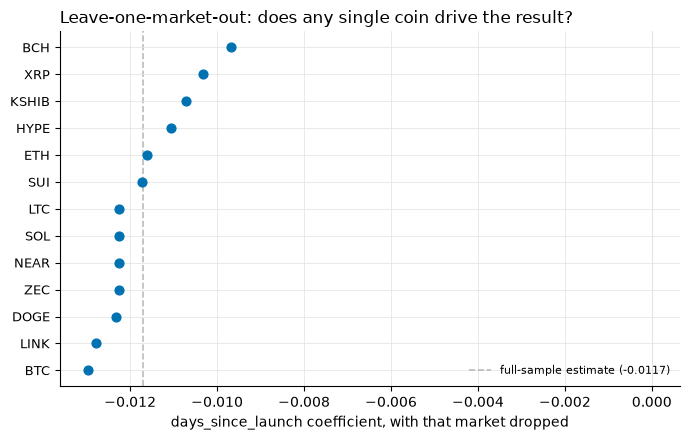

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
order = loo_df.sort_values("coef")
ax.scatter(order["coef"], range(len(order)), color=C_KALSHI, zorder=3, s=40)
ax.axvline(full_coef, color="#bbbbbb", linewidth=1.2, linestyle="--", zorder=1,
           label=f"full-sample estimate ({full_coef:.4f})")
ax.axvline(0, color="#dddddd", linewidth=0.8, zorder=0)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order["dropped"], fontsize=9)
ax.set_xlabel("days_since_launch coefficient, with that market dropped")
ax.set_title("Leave-one-market-out: does any single coin drive the result?", loc="left")
ax.legend(fontsize=8, frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

## 3. Sign test — does funding revert toward neutral, or just shrink?

The main finding is about the *size* of mispricing (|funding|). This asks a
complementary question about *direction*: is funding disproportionately
negative (shorts paid) early on, moving toward an even split as markets
mature — or does the sign imbalance persist even as the magnitude shrinks?
Restricted to nonzero readings only, comparing days 0–14 to day 21+, with a
two-proportion z-test.

In [6]:
nonzero = reg_df[reg_df["funding_rate"] != 0].copy()
nonzero["is_negative"] = nonzero["funding_rate"] < 0

early = nonzero[nonzero["days_since_launch"] < 14]
late = nonzero[nonzero["days_since_launch"] >= 21]

counts = [early["is_negative"].sum(), late["is_negative"].sum()]
nobs = [len(early), len(late)]
stat, pval = proportions_ztest(counts, nobs)

print(f"{'period':14} {'n (nonzero)':>12} {'% negative':>12}")
print(f"{'days 0-14':14} {nobs[0]:12} {counts[0]/nobs[0]*100:11.1f}%")
print(f"{'day 21+':14} {nobs[1]:12} {counts[1]/nobs[1]*100:11.1f}%")
print(f"\ntwo-proportion z-test: z = {stat:.3f}, p = {pval:.2e}")

period          n (nonzero)   % negative
days 0-14               198        91.9%
day 21+                 186        55.4%

two-proportion z-test: z = 8.181, p = 2.81e-16


## 4. Does the data actually look linear?

A LOWESS curve makes no assumption about the shape of the decay — it just
traces whatever the data does, locally. Plotted alongside the straight
regression line to see how much the linear assumption is actually costing us.

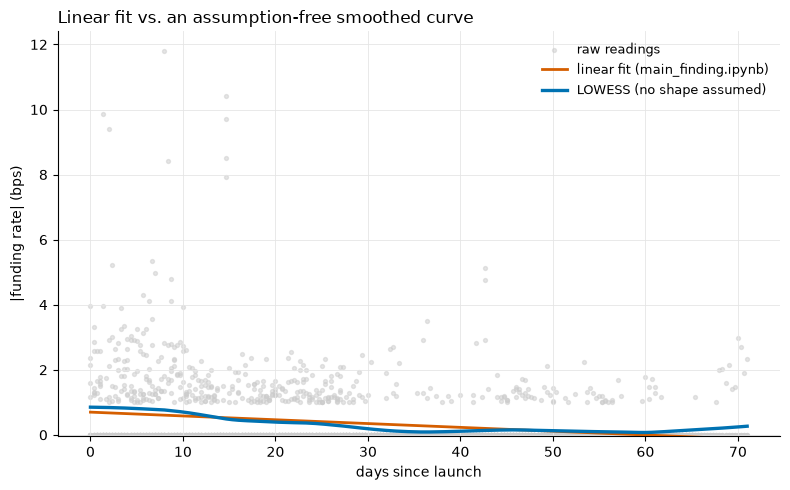

In [7]:
x = reg_df["days_since_launch"].values
y = reg_df["abs_funding_bps"].values

# it=0 disables LOWESS's default outlier-robustifying iterations, which
# otherwise treat the genuine early spikes as noise to downweight -- with
# ~80% of readings exactly 0, that robustifying procedure collapses the
# curve to zero almost everywhere instead of tracing the real decay.
smoothed = lowess(y, x, frac=0.25, it=0, return_sorted=True)

xs = np.linspace(x.min(), x.max(), 200)
linear_pred = model_hc1.params["Intercept"] + model_hc1.params["days_since_launch"] * xs

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=8, color="#cccccc", alpha=0.5, zorder=1, label="raw readings")
ax.plot(xs, linear_pred, color=C_OKX, linewidth=2, zorder=3, label="linear fit (main_finding.ipynb)")
ax.plot(smoothed[:, 0], smoothed[:, 1], color=C_KALSHI, linewidth=2.4, zorder=4, label="LOWESS (no shape assumed)")
ax.axhline(0, color="#e5e5e5", linewidth=0.8, zorder=0)
ax.set_xlabel("days since launch")
ax.set_ylabel("|funding rate| (bps)")
ax.set_ylim(bottom=-0.05)
ax.legend(fontsize=9, frameon=False)
ax.set_title("Linear fit vs. an assumption-free smoothed curve", loc="left")
fig.tight_layout()
plt.show()

## 5. Exponential decay fit

AHJ's theory frames convergence as happening at a random time with a
*constant hazard rate* κ — which implies exponential decay of the deviation,
not linear. Fit `|funding| = a * exp(-b * days_since_launch)` directly via
nonlinear least squares (handles the exact-zero readings natively, unlike a
log transform), and compare its fit quality to the linear model on the same
raw data.

In [8]:
def exp_decay(t, a, b):
    return a * np.exp(-b * t)

popt, pcov = curve_fit(exp_decay, x, y, p0=[0.8, 0.05], maxfev=10000)
a_hat, b_hat = popt
b_se = np.sqrt(np.diag(pcov))[1]
half_life = np.log(2) / b_hat

ss_tot = np.sum((y - y.mean()) ** 2)
ss_res_exp = np.sum((y - exp_decay(x, *popt)) ** 2)
ss_res_lin = np.sum((y - (model_hc1.params["Intercept"] + model_hc1.params["days_since_launch"] * x)) ** 2)
pseudo_r2_exp = 1 - ss_res_exp / ss_tot
pseudo_r2_lin = 1 - ss_res_lin / ss_tot

print(f"fitted: |funding| = {a_hat:.4f} * exp(-{b_hat:.4f} * days_since_launch)")
print(f"implied kappa (decay rate): {b_hat:.4f} per day  (s.e. {b_se:.4f})")
print(f"implied half-life: {half_life:.1f} days")
print()
print(f"{'model':10} {'R2 (or pseudo-R2)':>20}")
print(f"{'linear':10} {pseudo_r2_lin:20.4f}")
print(f"{'exponential':10} {pseudo_r2_exp:20.4f}")

fitted: |funding| = 0.9905 * exp(-0.0466 * days_since_launch)
implied kappa (decay rate): 0.0466 per day  (s.e. 0.0040)
implied half-life: 14.9 days

model         R2 (or pseudo-R2)
linear                   0.0671
exponential               0.0841


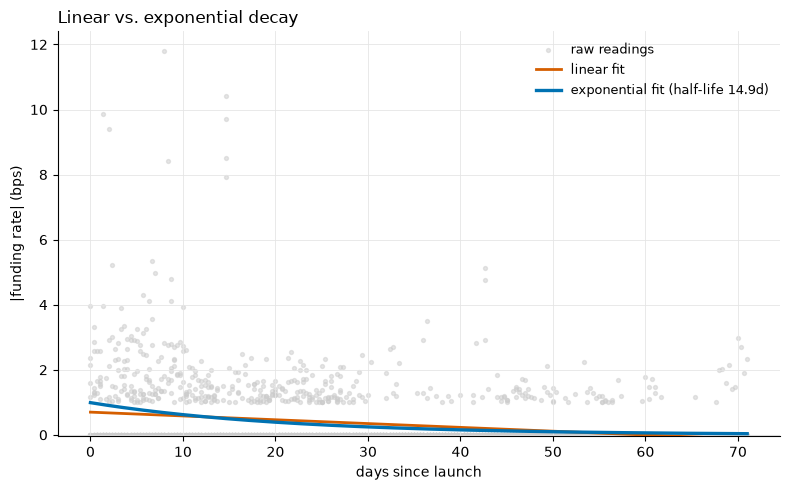

In [9]:
exp_pred = exp_decay(xs, *popt)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=8, color="#cccccc", alpha=0.5, zorder=1, label="raw readings")
ax.plot(xs, linear_pred, color=C_OKX, linewidth=2, zorder=3, label="linear fit")
ax.plot(xs, exp_pred, color=C_KALSHI, linewidth=2.4, zorder=4,
         label=f"exponential fit (half-life {half_life:.1f}d)")
ax.axhline(0, color="#e5e5e5", linewidth=0.8, zorder=0)
ax.set_xlabel("days since launch")
ax.set_ylabel("|funding rate| (bps)")
ax.set_ylim(bottom=-0.05)
ax.legend(fontsize=9, frameon=False)
ax.set_title("Linear vs. exponential decay", loc="left")
fig.tight_layout()
plt.show()

## Summary

In [10]:
summary = pd.DataFrame([
    {"check": "Cluster-robust SE (by market)",
     "headline": f"slope {model_cluster.params['days_since_launch']:.4f}, p={model_cluster.pvalues['days_since_launch']:.2e}",
     "verdict": "survives" if model_cluster.pvalues["days_since_launch"] < 0.05 else "does not survive"},
    {"check": "Leave-one-market-out (13 reruns)",
     "headline": f"coef range [{loo_df['coef'].min():.4f}, {loo_df['coef'].max():.4f}]",
     "verdict": "survives, all 13 negative & p<0.01" if (loo_df['coef'] < 0).all() and (loo_df['p_value'] < 0.01).all() else "mixed"},
    {"check": "Sign test (days 0-14 vs day 21+)",
     "headline": f"{counts[0]/nobs[0]*100:.0f}% neg. early vs {counts[1]/nobs[1]*100:.0f}% neg. late, p={pval:.2e}",
     "verdict": "reverts toward neutral" if pval < 0.05 else "no significant shift"},
    {"check": "LOWESS vs. linear shape",
     "headline": "visual comparison, see chart",
     "verdict": "see chart"},
    {"check": "Exponential decay fit",
     "headline": f"half-life {half_life:.1f} days, pseudo-R2 {pseudo_r2_exp:.3f} vs linear {pseudo_r2_lin:.3f}",
     "verdict": "better fit" if pseudo_r2_exp > pseudo_r2_lin else "linear fits as well or better"},
])

summary.style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}]
).hide(axis="index")

check,headline,verdict
Cluster-robust SE (by market),"slope -0.0117, p=3.60e-04",survives
Leave-one-market-out (13 reruns),"coef range [-0.0130, -0.0097]","survives, all 13 negative & p<0.01"
Sign test (days 0-14 vs day 21+),"92% neg. early vs 55% neg. late, p=2.81e-16",reverts toward neutral
LOWESS vs. linear shape,"visual comparison, see chart",see chart
Exponential decay fit,"half-life 14.9 days, pseudo-R2 0.084 vs linear 0.067",better fit
